# Predictive Maintenance Machine Learning Project
**Course:** Artificial Intelligence  
**Objective:** Build a machine learning model to predict equipment failure based on sensor readings. This proactive approach helps in reducing downtime and saving operational costs.

In [1]:
# Data Manipulation and Visualization
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore') # لإخفاء التحذيرات غير المهمة أثناء العرض

# Machine Learning: Preprocessing & Models
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
# Load the dataset
dataset_path ="data/ai4i2020.csv"
df = pd.read_csv(dataset_path)

print("Dataset loaded successfully!")
# Display the first 5 rows to verify
display(df.head())

Dataset loaded successfully!


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


# 2. Data Understanding and Cleaning
In this section, we will:
- Understand the structure and statistical summary of the dataset.
- Check for missing values and duplicates.
- Drop irrelevant columns (`UDI`, `Product ID`) that do not help in predicting machine failure.

In [3]:
# Display dataset info and shape
print(f"Dataset Shape: {df.shape}")
print("\n--- Dataset Info ---")
df.info()

# Check for missing values
print("\n--- Missing Values ---")
print(df.isnull().sum())

# Check for duplicates
duplicates = df.duplicated().sum()
print(f"\n--- Duplicates ---")
print(f"Number of duplicated rows: {duplicates}")

if duplicates > 0:
    df.drop_duplicates(inplace=True)
    print("Duplicates removed.")

Dataset Shape: (10000, 14)

--- Dataset Info ---
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  str    
 2   Type                     10000 non-null  str    
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null

### Dropping Irrelevant Columns
The columns `UDI` and `Product ID` are simply identifiers. They do not contain any physical or operational meaning for the machine, so we drop them to avoid confusing the machine learning model.

In [4]:
# Drop irrelevant columns
columns_to_drop = ['UDI', 'Product ID']
df = df.drop(columns=columns_to_drop)

print(f"Columns dropped: {columns_to_drop}")
print("\nRemaining columns:")
print(df.columns.tolist())

Columns dropped: ['UDI', 'Product ID']

Remaining columns:
['Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']


# 3. Exploratory Data Analysis (EDA)
In this phase, we visualize the data to understand the distribution of our target variable and the relationships (correlations) between different sensor readings.

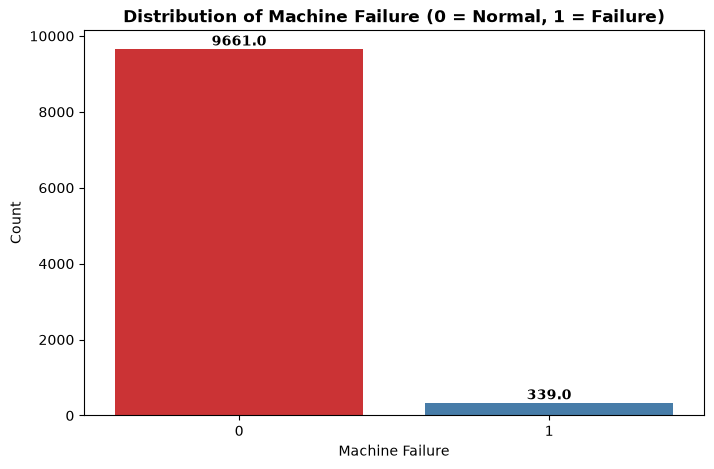

Observation: The dataset is highly imbalanced. Machine failures represent a very small percentage of the data.


In [6]:
# 1. Visualize the Target Variable Distribution
plt.figure(figsize=(8, 5))
ax = sns.countplot(data=df, x='Machine failure', palette='Set1')
plt.title('Distribution of Machine Failure (0 = Normal, 1 = Failure)', fontweight='bold')
plt.xlabel('Machine Failure')
plt.ylabel('Count')

# Add counts above bars
for p in ax.patches:
    ax.annotate(f'{p.get_height()}', (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='bottom', fontweight='bold')

plt.show()

print("Observation: The dataset is highly imbalanced. Machine failures represent a very small percentage of the data.")

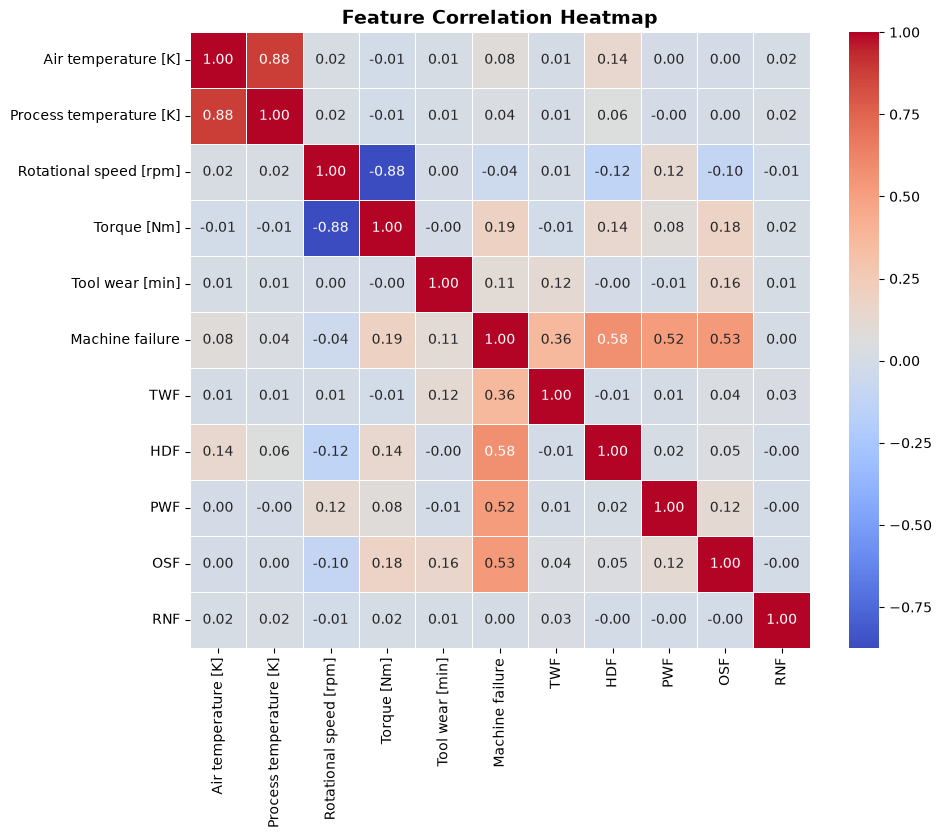

In [7]:
# 2. Correlation Heatmap
plt.figure(figsize=(10, 8))
# Select only numerical columns for correlation
numeric_cols = df.select_dtypes(include=[np.number])
correlation_matrix = numeric_cols.corr()

sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Feature Correlation Heatmap', fontsize=14, fontweight='bold')
plt.show()

# 4. Outlier Detection
We use Boxplots to visualize outliers in continuous sensor readings (e.g., Rotational speed, Torque). 

**Important Note on Outlier Treatment:** 
In predictive maintenance, outliers (extreme high temperatures or abnormal rotational speeds) are often the exact physical indicators of an impending machine failure. Removing them would destroy the model's ability to learn failure patterns. Therefore, we will detect and visualize them, but we **will not remove them**.

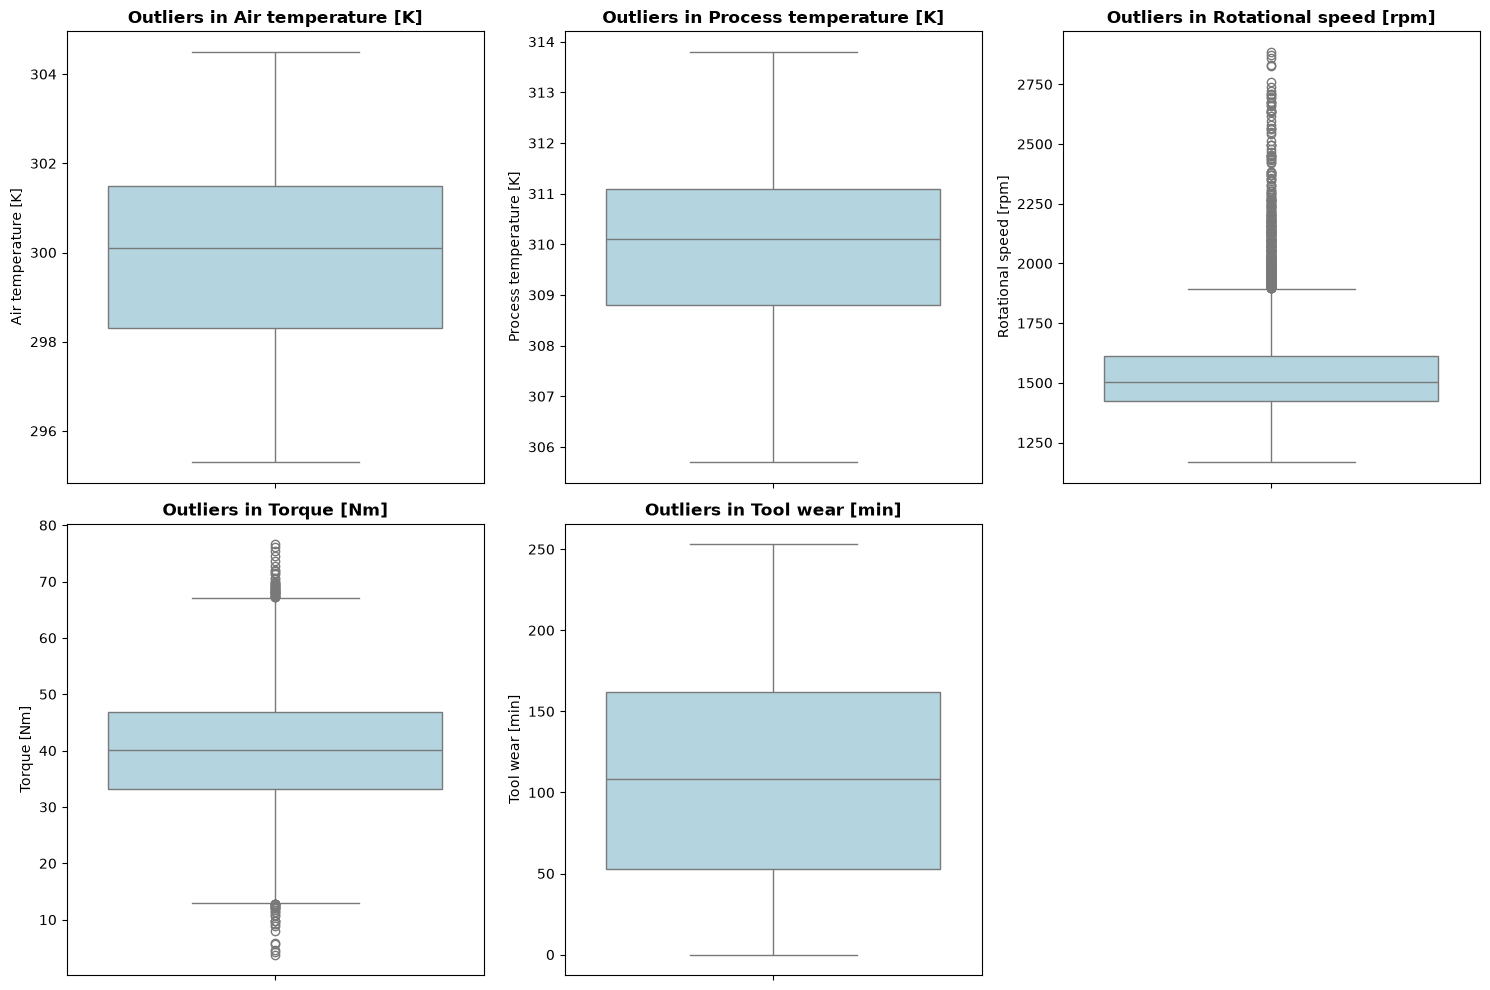

In [8]:
# Plotting Boxplots for sensor readings
features_to_check = ['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']

plt.figure(figsize=(15, 10))

for i, feature in enumerate(features_to_check, 1):
    plt.subplot(2, 3, i)
    sns.boxplot(data=df, y=feature, color='lightblue')
    plt.title(f'Outliers in {feature}', fontweight='bold')

plt.tight_layout()
plt.show()

# 5. Data Preprocessing
## 5.1 Preventing Data Leakage
The columns `TWF`, `HDF`, `PWF`, `OSF`, and `RNF` represent specific types of machine failures. Including them as features to predict the general `Machine failure` will cause **Data Leakage** (the model will cheat by looking at the failure type). We must drop them to build a robust model based *only* on sensor readings.

In [9]:
# Drop failure type columns to prevent data leakage
leakage_columns = ['TWF', 'HDF', 'PWF', 'OSF', 'RNF']
df = df.drop(columns=leakage_columns)

print(f"Dropped columns: {leakage_columns}")
print("\nFinal Features available for training:")
print(df.columns.tolist())

Dropped columns: ['TWF', 'HDF', 'PWF', 'OSF', 'RNF']

Final Features available for training:
['Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Machine failure']


## 5.2 Encoding Categorical Variables
Machine Learning models require numerical input. We need to convert the `Type` column (which contains text values: L, M, H for Low, Medium, High quality) into numerical values using `LabelEncoder`.

In [10]:
# Initialize LabelEncoder
encoder = LabelEncoder()

# Fit and transform the 'Type' column
df['Type'] = encoder.fit_transform(df['Type'])

# Display the mapping to understand what the numbers mean
mapping = dict(zip(encoder.classes_, encoder.transform(encoder.classes_)))
print(f"Mapping of 'Type' column: {mapping}")

# Display the first few rows to verify
display(df.head())

Mapping of 'Type' column: {'H': np.int64(0), 'L': np.int64(1), 'M': np.int64(2)}


,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure
0,2,298.1,308.6,1551,42.8,0,0
1,1,298.2,308.7,1408,46.3,3,0
2,1,298.1,308.5,1498,49.4,5,0
3,1,298.2,308.6,1433,39.5,7,0
4,1,298.2,308.7,1408,40.0,9,0


## 5.3 Train / Test Split & Feature Scaling
We split the data into Training (80%) and Testing (20%) sets. We use `stratify=y` to ensure the highly imbalanced ratio of machine failures is maintained in both sets.
Finally, we scale the numerical features using `StandardScaler` and **export the scaler** using `pickle` for deployment.

In [11]:
import os
import pickle

# Define Features (X) and Target (y)
X = df.drop(columns=['Machine failure'])
y = df['Machine failure']

# 1. Train/Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Training data shape: {X_train.shape}")
print(f"Testing data shape: {X_test.shape}")

# 2. Feature Scaling
scaler = StandardScaler()

# Fit on training data ONLY, then transform both
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 3. EXPORTING SCALER AND COLUMNS
# Create a 'model' directory if it doesn't exist
os.makedirs("model", exist_ok=True)

# Save the scaler
with open("model/scaler.pkl", "wb") as file:
    pickle.dump(scaler, file)

# Save the column names for the web app
with open("model/columns.pkl", "wb") as file:
    pickle.dump(X_train.columns.tolist(), file)

print("\nFeatures scaled successfully!")
print("Files 'scaler.pkl' and 'columns.pkl' saved in the 'model' directory.")

Training data shape: (8000, 6)
Testing data shape: (2000, 6)

Features scaled successfully!
Files 'scaler.pkl' and 'columns.pkl' saved in the 'model' directory.


# 6. Model Training
We selected the **Random Forest Classifier** because it is robust, handles non-linear relationships well, and is highly effective for imbalanced datasets like ours.

In [12]:
# Initialize the Random Forest model
# random_state ensures reproducibility, class_weight='balanced' helps with the imbalanced target
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced')

# Train the model
rf_model.fit(X_train_scaled, y_train)

print("Random Forest Model trained successfully!")

Random Forest Model trained successfully!


### 6.1 Hyperparameter Tuning (Fine-Tuning)
To strictly fulfill the project requirements and maximize performance, we apply **GridSearchCV**. This technique trains the `RandomForestClassifier` multiple times across a grid of hyperparameters to find the optimal configuration for predicting machine failures.

In [17]:
from sklearn.model_selection import GridSearchCV

# 1. Define the parameters to tune (The Grid)
param_grid = {
    'n_estimators': [50, 100, 150],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5, 10]
}

# 2. Initialize the Grid Search
print("Starting Hyperparameter Tuning... This may take a minute.")
grid_search = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42, class_weight='balanced'),
    param_grid=param_grid,
    cv=5, # 5-fold cross-validation
    scoring='accuracy',
    n_jobs=-1 # Use all computer processors
)

# 3. Fit the Grid Search to the data (The actual Fine-Tuning process)
grid_search.fit(X_train_scaled, y_train)

# 4. Extract the best model
best_rf_model = grid_search.best_estimator_

print(f"\nFine-Tuning Completed Successfully!")
print(f"Best Hyperparameters found: {grid_search.best_params_}")

Starting Hyperparameter Tuning... This may take a minute.

Fine-Tuning Completed Successfully!
Best Hyperparameters found: {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 100}


# 7. Model Evaluation
In an imbalanced dataset, **Accuracy** alone is not enough. We must also look at **Precision, Recall, and the F1-score** for the minority class (Machine Failure) to ensure the model is actually predicting failures, not just guessing 'Normal' every time.

Model Accuracy: 98.25%

--- Classification Report ---
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      1932
           1       0.75      0.74      0.74        68

    accuracy                           0.98      2000
   macro avg       0.87      0.86      0.87      2000
weighted avg       0.98      0.98      0.98      2000



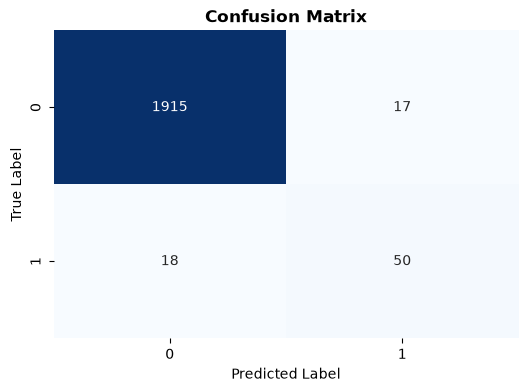

In [20]:
# Make predictions on the testing set
y_pred = best_rf_model.predict(X_test_scaled)

# 1. Calculate Accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Model Accuracy: {accuracy * 100:.2f}%\n")

# 2. Classification Report
print("--- Classification Report ---")
print(classification_report(y_test, y_pred))

# 3. Confusion Matrix Visualization
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title('Confusion Matrix', fontweight='bold')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

# 8. Training Second Algorithm (Logistic Regression)
To strictly meet the project requirement of comparing at least two algorithms, we will train a `LogisticRegression` model and evaluate its performance against our tuned `Random Forest`.

In [22]:
# Initialize and train Logistic Regression
lr_model = LogisticRegression(random_state=42, class_weight='balanced', max_iter=1000)
lr_model.fit(X_train_scaled, y_train)

# Predict and evaluate
y_pred_lr = lr_model.predict(X_test_scaled)
lr_accuracy = accuracy_score(y_test, y_pred_lr)

print(f"Logistic Regression Accuracy: {lr_accuracy * 100:.2f}%\n")
print("--- Logistic Regression Classification Report ---")
print(classification_report(y_test, y_pred_lr))

Logistic Regression Accuracy: 82.10%

--- Logistic Regression Classification Report ---
              precision    recall  f1-score   support

           0       0.99      0.82      0.90      1932
           1       0.14      0.84      0.24        68

    accuracy                           0.82      2000
   macro avg       0.57      0.83      0.57      2000
weighted avg       0.96      0.82      0.88      2000



# 9. Algorithms Comparison & Final Model Export
We will dynamically compare the accuracy of both models. The algorithm with the highest accuracy will be automatically selected as the `best_model.pkl` and exported for deployment in our Web UI.

In [24]:
# Compare Accuracies (Assuming rf_accuracy was defined earlier, if not, we recalculate it)
y_pred_rf = best_rf_model.predict(X_test_scaled)
rf_accuracy = accuracy_score(y_test, y_pred_rf)

print("=== FINAL COMPARISON ===")
print(f"Random Forest (Tuned) Accuracy: {rf_accuracy * 100:.2f}%")
print(f"Logistic Regression Accuracy:     {lr_accuracy * 100:.2f}%")

# Select the winner
if rf_accuracy >= lr_accuracy:
    print("\n🏆 Winner: Random Forest! Exporting as final model...")
    final_model = best_rf_model
else:
    print("\n🏆 Winner: Logistic Regression! Exporting as final model...")
    final_model = lr_model

# Export the winning model
with open("model/final_model.pkl", "wb") as file:
    pickle.dump(final_model, file)

print("\nSuccess: 'final_model.pkl' is successfully saved and ready for the Web Application.")

=== FINAL COMPARISON ===
Random Forest (Tuned) Accuracy: 98.25%
Logistic Regression Accuracy:     82.10%

🏆 Winner: Random Forest! Exporting as final model...

Success: 'final_model.pkl' is successfully saved and ready for the Web Application.


# 10. Exporting the Final Model
To integrate this Machine Learning model into a real-world web application (Deployment), we must save the trained model using `pickle`.

In [26]:
# Save the trained Random Forest model
with open("model/rf_model.pkl", "wb") as file:
    pickle.dump(best_rf_model, file)

print("Trained Model 'rf_model.pkl' saved successfully in the 'model' directory!")
print("\n--- All Exported Files Ready for Deployment ---")
print(os.listdir("model"))

Trained Model 'rf_model.pkl' saved successfully in the 'model' directory!

--- All Exported Files Ready for Deployment ---
['columns.pkl', 'final_model.pkl', 'rf_model.pkl', 'scaler.pkl']
